<a href="https://colab.research.google.com/github/Beatricepapi/ml-campus_data_project-colab/blob/main/Beatrice_Papi_Machine_Learning_with_Python_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Campus Synthetic Dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

#**Project Introduction**

##Project Title
Exploring Campus Nature and Human Experience Through Data and Machine Learning

###Research Question
How can data collected during a campus nature walk be used to investigate the relationship between environmental characteristics and human experience?

###Project Aim
The aim of this project is to explore how different environmental characteristics around the ATU Galway campus may relate to people's wellbeing and experiences.

Using Python, I will clean, explore and visualise the campus dataset to identify patterns and possible relationships between environmental factors, such as sound levels, weather, foot traffic and natural features, and human experiences, such as stress, wellbeing and connection with nature.

I will also apply machine-learning techniques to investigate these patterns and evaluate the results.

##Weekly Decision Logs

### Decision 1 – Initial Dataset Cleaning – 08/10/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | My dataset contained 994 rows and 27 columns, with many empty rows and missing values. |
| **Decision Taken** | I created a copy of the dataset, removed rows without a location and deleted four completely empty columns. |
| **Justification** | I wanted to keep the original data unchanged and work only with the recorded observations. |
| **Evidence** | The dataset was reduced from 994 rows and 27 columns to 135 rows and 23 columns. |
| **AI Use** | I used ChatGPT to help me understand the Pandas cleaning commands. |
| **Reflection / Learning** | I learned how to inspect a dataset, identify missing data and remove unnecessary rows and columns. |

### Decision 2 – Handling Missing Values and Inconsistent Text – 15/10/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | After cleaning, some nature-related columns still had missing values and inconsistent text entries. |
| **Decision Taken** | I checked the remaining missing values and duplicates, kept missing values unchanged, and removed extra spaces from text entries. |
| **Justification** | I did not want to remove useful observations or treat missing values as if plants were absent. |
| **Evidence** | There were 0 duplicate rows. In the moss or lichen column, the two versions of `Some` were combined into 65 entries. |
| **AI Use** | I used ChatGPT to help identify a column-name error and understand text standardisation. |
| **Reflection / Learning** | I learned that small text differences can affect results and that missing values need careful consideration. |

### Decision 3 – Data Visualisation and Encoding – 22/10/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | I needed to visualise my data and prepare categorical variables for correlation analysis. |
| **Decision Taken** | I created bar charts, encoded sound levels, foot traffic, wellbeing, stress and ease ratings, and created a Spearman correlation heatmap. |
| **Justification** | I chose bar charts because they helped me compare observations. I used ordinal encoding because the categories have a natural order, and Spearman correlation to investigate relationships. |
| **Evidence** | All five variables were encoded successfully. The heatmap showed a correlation of 0.56 between sound level and foot traffic and −0.60 between wellbeing and stress. |
| **AI Use** | I used ChatGPT to help write Python code, correct errors, understand encoding and interpret the graphs. |
| **Reflection / Learning** | I learned how to convert categorical data into numbers and use a correlation matrix to identify relationships. I also learned that correlation does not prove causation. |

###Decision 4 – Choosing and Applying K-Means Clustering – 05/11/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | I needed to choose a machine-learning method to investigate patterns in my campus dataset. |
| **Decision Taken** | I decided to try K-Means Clustering using sound levels and foot traffic. I used the Elbow Method to help choose 3 clusters. |
| **Justification** | I wanted to see whether K-Means could group similar campus observations without using predefined labels. |
| **Evidence** | The model divided 135 observations into 3 clusters. The Silhouette Score was 0.784 and the inertia was 21.841. |
| **AI Use** | I used ChatGPT to help understand K-Means, write and correct the Python code, and interpret the results. |
| **Reflection / Learning** | I learned how K-Means groups similar observations and how to evaluate the clusters. I also learned that using encoded categorical data can affect the results. |

### Decision 5 – Linear Regression and Model Evaluation – 12/11/2026

| Question | My Decision |
|---|---|
| **Issue / Challenge** | I wanted to investigate whether sound levels and foot traffic could predict wellbeing ratings. |
| **Decision Taken** | I used Linear Regression, divided my dataset into training and testing sets, and evaluated the predictions using MAE, RMSE and R². |
| **Justification** | I wanted to try another machine-learning method and compare its results with a simple baseline. |
| **Evidence** | The model had an MAE of 0.619, RMSE of 0.728 and R² of −0.018. Its predictions were only slightly better than the baseline MAE of 0.621. |
| **AI Use** | I used ChatGPT to help understand Linear Regression, correct encoding errors, write Python code and interpret the results. |
| **Reflection / Learning** | I learned that machine-learning models do not always make accurate predictions and that evaluating results is important. I also learned that Linear Regression has limitations when using ordinal wellbeing ratings. |

#**Dataset**

In [ ]:
df = pd.read_csv(
    '/content/drive/MyDrive/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)


##Inspect the Dataset structure

In [ ]:
print(df.shape)
print('\nThe first 5 rows of my dataset:')
print(df.head())


(994, 27)

The first 5 rows of my dataset:
  recorder_id       date                        location        weather  \
0     R26_001  9/22/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  9/22/2026                L02 LibraryGreen          Sunny   
2     R26_001  9/22/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  9/22/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  9/22/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_sound_type_nature  ...    wellbeing_rating  \
0           

##Check Dataset information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insect

##Check for missing values

In [ ]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
recorder_id                              795
date                                     859
location                                 859
weather                                  859
temperature_c                            859
sound level                              859
foot_traffic                             859
primary_sound_type_urban                 859
other_sound_type_urban                   862
primary_sound_type_nature                859
other_sound_type_nature                  861
insects_count                            859
birds_count                              859
trees_presence                           864
native_or_wild_plant_presence            871
ornnamental_or_planted_plant_presence    897
moss_or_lichen_presence                  895
wellbeing_rating                         859
ease_rating                              859
stress_rating                            859
nature_connection_experience_rating      859
most_notable_nature_element           

##Check for duplicate rows

In [ ]:
print("\nDuplicate rows:")
print(df.duplicated().sum())



Duplicate rows:
844


##Create a copy o the original Dataset

In [ ]:
df_clean = df.copy()

##Remove rows without a reorded location

In [ ]:
df_clean = df_clean.dropna(subset=['location'])

##Remove completely empty columns

In [ ]:
df_clean = df_clean.dropna(axis=1, how='all')

##Display the cleaned dataset dimensions

In [ ]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (994, 27)
Cleaned dataset: (135, 23)


##Display the first five cleaned rows

In [ ]:
display(df_clean.head())


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,...,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,...,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,...,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,...,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,...,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN


#**Check Remaining Missing Values and Duplicates**


##Check missing values in the cleaned dataset

In [ ]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
recorder_id                               0
date                                      0
location                                  0
weather                                   0
temperature_c                             0
sound level                               0
foot_traffic                              0
primary_sound_type_urban                  0
other_sound_type_urban                    3
primary_sound_type_nature                 0
other_sound_type_nature                   2
insects_count                             0
birds_count                               0
trees_presence                            5
native_or_wild_plant_presence            12
ornnamental_or_planted_plant_presence    38
moss_or_lichen_presence                  36
wellbeing_rating                          0
ease_rating                               0
stress_rating                             0
nature_connection_experience_rating       0
most_notable_nature_element              15
o

##Check duplicate rows in the cleaned dataset

In [ ]:
print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())



Duplicate rows after cleaning:
0


##Inspect the values in nature-related columns

In [ ]:
nature_columns = [
    'trees_presence',
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence'
]

for col in nature_columns:
    print("\n", col)
    print(df_clean[col].value_counts(dropna=False))



 trees_presence
trees_presence
Many          101
One or two     29
NaN             5
Name: count, dtype: int64

 native_or_wild_plant_presence
native_or_wild_plant_presence
Some     78
Many     45
NaN      12
Name: count, dtype: int64

 ornnamental_or_planted_plant_presence
ornnamental_or_planted_plant_presence
Some     60
NaN      38
Many     37
Name: count, dtype: int64

 moss_or_lichen_presence
moss_or_lichen_presence
Some     63
NaN      36
Many     34
Some      2
Name: count, dtype: int64


##Remove extra spaces from text values

In [ ]:
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

##Check moss or lichen values again

In [ ]:
print(df_clean['moss_or_lichen_presence'].value_counts(dropna=False))


moss_or_lichen_presence
Some    65
NaN     36
Many    34
Name: count, dtype: int64


#**Data Exploration and Visualisation**

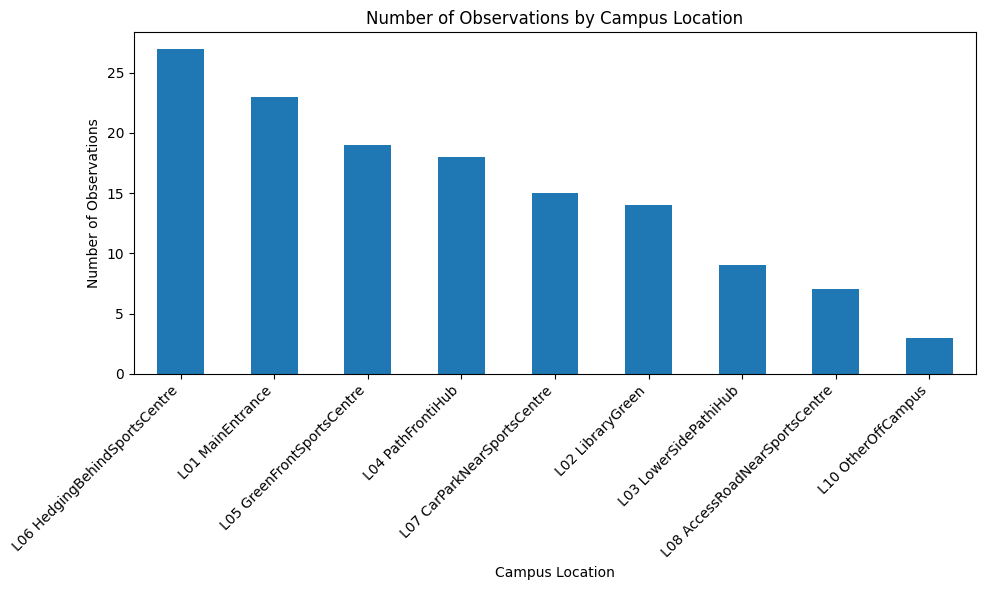

In [ ]:

import matplotlib.pyplot as plt

#Count observations at each campus location
location_counts = df_clean['location'].value_counts()

#Create a bar chart
plt.figure(figsize=(10, 6))
location_counts.plot(kind='bar')

plt.title('Number of Observations by Campus Location')
plt.xlabel('Campus Location')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


###Interpretation - Number of Observations by Campus Location

I chose to use a bar chart because this is how I was imagining the data in my head. I thought it would be the easiest way to visually compare the number of observations collected at each campus location and clearly see the differences between them.

The bar chart shows that L06 HedgingBehindSportsCentre had the highest number of observations (27), followed by L01 MainEntrance (23). L10 OtherOffCampus had the lowest number of observations (3).

Looking at the graph, I noticed that the observations were not evenly distributed across the different locations. Some places had many more observations than others.

I think this is important because locations with more observations could have a greater influence on the overall results, while locations with fewer observations might be harder to compare reliably.

Creating this graph helped me understand how the observations were distributed across campus. It also gave me a clearer picture of the dataset before moving on to investigate how environmental factors, such as sound levels and natural features, might be related to people's stress and wellbeing.

##Exploring Sound Levels and Stress

In this section, I wanted to investigate whether different sound levels around the campus were related to how stressed or calm people felt.

I used the `sound_level` and `stress_rating` columns from my cleaned dataset. Both columns contain categorical data, so I decided to use `pd.crosstab()` to compare them.

I also used `normalize='index'` to calculate percentages for each sound level. I thought percentages would make the comparison easier because the number of observations was not the same for every sound category.

###Compare sound levels with stress ratings

stress_rating,Mostly calm,Neutral,Stressful,Very calm,Very stressful
sound level,,,,,
Loud,41.2,41.2,11.8,5.9,0.0
Moderate,45.0,30.0,5.0,18.3,1.7
Quiet,43.1,22.4,3.4,31.0,0.0


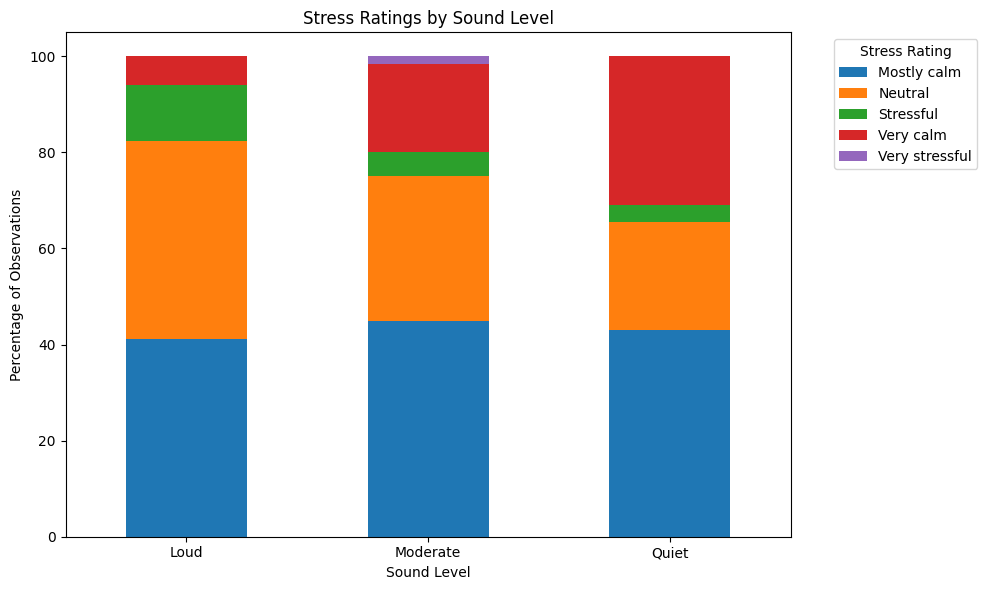

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

sound_stress = pd.crosstab(
    df_clean['sound level'],
    df_clean['stress_rating'],
    normalize='index'
) * 100

display(sound_stress.round(1))

sound_stress.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Stress Ratings by Sound Level')
plt.xlabel('Sound Level')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)
plt.legend(title='Stress Rating', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

###Interpretation - Stress Rating by Sound Level

I chose to use a stacked bar chart because I wanted to compare the different stress ratings across loud, moderate and quiet environments. I first learned how to use this type of chart during a Maths Lab, so I was already familiar with it. I thought it would be a good way to visualise the results because it allows me to compare the percentages of each stress category across different sound levels.

Looking at the graph, I noticed that quiet environments had the highest percentage of people reporting feeling very calm (31%), compared with moderate environments (18.3%) and loud environments (5.9%).

I also noticed that the percentage of stressful ratings was higher in loud environments (11.8%) than in quiet environments (3.4%).

I found this interesting because it suggests that quieter environments may be associated with feeling calmer, while louder environments may be associated with higher stress levels.

However, I understand that this graph does not prove that noise directly causes stress, as other environmental factors could also influence how people feel.

Creating this graph helped me apply something I had previously learned during my Maths Lab to a real dataset. It also helped me begin investigating the relationship between environmental characteristics and human experience, which is the main research question of my project.

##Exploring Trees and Wellbeing

In this section, I want to investigate whether the number of trees observed around campus is related to people's wellbeing.

I will use the `trees_presence` and `wellbeing_rating` columns from my cleaned dataset. Both columns contain categorical data, so I will use `pd.crosstab()` to compare the responses and calculate percentages.

I also noticed that five observations have missing tree-presence values, so these will not be included in the comparison.

Wellbeing Ratings by Tree Presence:


wellbeing_rating,Low wellbeing,Neutral,Positive wellbeing,Very low wellbeing,Very positive wellbeing
trees_presence,,,,,
Many,5.9,28.7,48.5,1.0,15.8
One or two,3.4,27.6,58.6,3.4,6.9


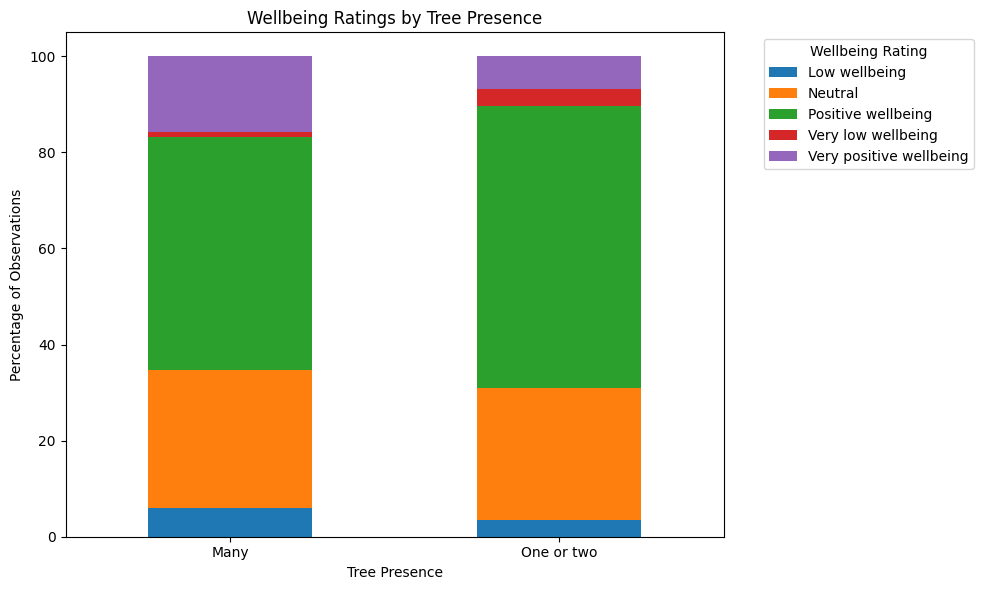

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#Calculate percentages for each tree-presence category
trees_wellbeing = pd.crosstab(
    df_clean['trees_presence'],
    df_clean['wellbeing_rating'],
    normalize='index'
) * 100

print("Wellbeing Ratings by Tree Presence:")
display(trees_wellbeing.round(1))

#Create a stacked bar chart
trees_wellbeing.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Wellbeing Ratings by Tree Presence')
plt.xlabel('Tree Presence')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)

plt.legend(
    title='Wellbeing Rating',
    bbox_to_anchor=(1.05, 1)
)

plt.tight_layout()
plt.show()


###Interpretation - Wellbeing Ratings by Tree Presence

I chose to use a stacked bar chart again because I found it useful when comparing sound levels and stress ratings.

Looking at the graph, I noticed that observations where many trees were present had a higher percentage of very positive wellbeing ratings (15.8%) compared with observations where only one or two trees were present (6.9%).

However, I also noticed that positive wellbeing ratings were higher in areas with one or two trees (58.6%) compared with areas with many trees (48.5%).

I found this interesting because I initially thought that having more trees would always be associated with better wellbeing, but the graph showed that the relationship is not so simple.

This helped me understand that data analysis can sometimes give unexpected results and that it is important to look at all the categories rather than focusing on just one.

I also understand that the graph does not prove that trees directly affect wellbeing, because other environmental factors could influence how people feel. In addition, there were fewer observations in the one-or-two-trees category, which could affect the comparison.

#**Preparing Variables for Correlation Analysis**

In this section, I want to prepare some of the variables in my dataset for correlation analysis.

I noticed that several columns contain text values instead of numbers, such as Quiet, Moderate and Loud for sound levels.

To analyse relationships between these variables, I need to convert suitable categories into numerical values. I learned from my lecturer's example that this process is called encoding.

I will use ordinal encoding for variables that have a natural order. For example, sound levels can be ordered from Quiet to Moderate to Loud.

I will keep the original columns unchanged and create new encoded columns. This will allow me to compare the original values with the numerical values and check that the encoding worked correctly.

In [ ]:
sound_mapping = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

#Create a new numerical column for sound levels
df_clean['sound_level_encoded'] = df_clean['sound level'].map(sound_mapping)

display(
    df_clean[['sound level', 'sound_level_encoded']]
    .drop_duplicates()
    .sort_values(by='sound_level_encoded')
)

#Check for missing or unmapped values
print("\nUnmapped values:")
print(df_clean['sound_level_encoded'].isnull().sum())

,sound level,sound_level_encoded
0,Quiet,0
1,Moderate,1
32,Loud,2



Unmapped values:
0


###Interpretation - Sound Level Encoding

I converted the sound levels into numerical values because I wanted to prepare my dataset for correlation analysis.

I used ordinal encoding because the sound levels have a natural order: Quiet, Moderate and Loud. I assigned 0 to Quiet, 1 to Moderate and 2 to Loud.

After running the code, I checked the results and confirmed that all three sound categories were converted correctly, with no unmapped values.

I also kept the original sound level column unchanged so I could still use the original categories when interpreting the data.

##Foot Traffic Encoding


I decided to encode the foot traffic column because I wanted to prepare another environmental variable for correlation analysis.

Foot traffic is ordinal categorical data because its categories have a natural order: Low, Moderate and High.

I will assign numerical values from 0 to 2 and create a new column so I can keep the original data unchanged. I will then check that all the values have been converted correctly.

In [ ]:
df_clean['foot_traffic'] = (
    df_clean['foot_traffic']
    .str.strip()
    .str.capitalize()
)

foot_traffic_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

df_clean['foot_traffic_encoded'] = (
    df_clean['foot_traffic'].map(foot_traffic_mapping)
)

print("Foot Traffic Encoding:")

display(
    df_clean[['foot_traffic', 'foot_traffic_encoded']]
    .drop_duplicates()
    .sort_values(by='foot_traffic_encoded')
)

print("\nUnmapped values:")
print(df_clean['foot_traffic_encoded'].isnull().sum())


Foot Traffic Encoding:


,foot_traffic,foot_traffic_encoded
0,Low,0
12,Moderate,1
30,High,2



Unmapped values:
0


###Interpretation - Foot Traffic Encoding

I converted the foot traffic categories into numerical values because I wanted to prepare my dataset for correlation analysis.

When I first ran the code, I noticed that one value was not encoded correctly. After checking the results, I discovered that one observation was written as `low` instead of `Low`.

I corrected this by standardising the text values and then using ordinal encoding to assign Low = 0, Moderate = 1 and High = 2.

After running the code again, all the categories were successfully converted, with zero unmapped values.

##Wellbeing Rating Encoding

In this section, I want to convert the wellbeing ratings into numerical values to prepare my dataset for correlation analysis.

The wellbeing ratings are ordinal categorical data because they have a natural order, from very low wellbeing to very positive wellbeing.

I will use numerical values from 0 to 4 and create a new column while keeping the original wellbeing ratings unchanged. I will then check the results to make sure all categories have been encoded correctly.

In [ ]:
wellbeing_mapping = {
    'Very low wellbeing': 0,
    'Low wellbeing': 1,
    'Neutral': 2,
    'Positive wellbeing': 3,
    'Very positive wellbeing': 4
}

df_clean['wellbeing_encoded'] = (
    df_clean['wellbeing_rating'].map(wellbeing_mapping)
)

print("Wellbeing Rating Encoding:")

display(
    df_clean[['wellbeing_rating', 'wellbeing_encoded']]
    .drop_duplicates()
    .sort_values(by='wellbeing_encoded')
)

print("\nUnmapped values:")
print(df_clean['wellbeing_encoded'].isnull().sum())


Wellbeing Rating Encoding:


,wellbeing_rating,wellbeing_encoded
22,Very low wellbeing,0
23,Low wellbeing,1
6,Neutral,2
0,Positive wellbeing,3
9,Very positive wellbeing,4



Unmapped values:
0


###Interpretation - Wellbeing Rating Encoding

I converted the wellbeing ratings into numerical values because I wanted to prepare my dataset for correlation analysis.

I used ordinal encoding because the wellbeing categories have a natural order, from very low wellbeing to very positive wellbeing.

I assigned values from 0 to 4, with 0 representing very low wellbeing and 4 representing very positive wellbeing.

After running the code, I checked the results and confirmed that all five categories were converted correctly, with zero unmapped values.

##Stress Rating Encoding

In this section, I want to convert the stress ratings into numerical values to prepare my dataset for correlation analysis.

The stress ratings are ordinal categorical data because they have a natural order, from very calm to very stressful.

I decided to use ordinal encoding, assigning values from 0 to 4, where 0 represents very calm and 4 represents very stressful.

I will create a new column called `stress_encoded` while keeping the original stress ratings unchanged. I will then check that all categories have been converted correctly.

In [ ]:
stress_mapping = {
    'Very calm': 0,
    'Mostly calm': 1,
    'Neutral': 2,
    'Stressful': 3,
    'Very stressful': 4
}

df_clean['stress_encoded'] = (
    df_clean['stress_rating'].map(stress_mapping)
)

print("Stress Rating Encoding:")

display(
    df_clean[['stress_rating', 'stress_encoded']]
    .drop_duplicates()
    .sort_values(by='stress_encoded')
)

print("\nUnmapped values:")
print(df_clean['stress_encoded'].isnull().sum())


Stress Rating Encoding:


,stress_rating,stress_encoded
6,Very calm,0
2,Mostly calm,1
1,Neutral,2
0,Stressful,3
22,Very stressful,4



Unmapped values:
0


###Interpretation - Stress Rating Encoding

I used ordinal encoding to convert the five stress categories into numerical values, from Very calm = 0 to Very stressful = 4.

After running the code, I checked the results to make sure the numerical values matched the original stress categories.

This helped me understand how stress ratings can be represented numerically so that I can use them in correlation analysis.

By keeping the original column unchanged, I can still compare the numerical values with the original responses when interpreting my results.

##Ease Rating Encoding

In this section, I want to convert the ease ratings into numerical values to prepare my dataset for correlation analysis.

The ease ratings describe how comfortable or at ease people felt during the campus walk. These ratings are categorical data, and I need to check their categories before assigning numerical values.

I will use ordinal encoding if the categories have a natural order. I will also keep the original column unchanged so I can compare the encoded values with the original responses.

In [ ]:
print("Ease Rating Categories:")
print(df_clean['ease_rating'].value_counts(dropna=False))

print("\nUnique values:")
print(df_clean['ease_rating'].unique())


Ease Rating Categories:
ease_rating
Easy              58
Neutral           38
Vey easy          23
Slighly uneasy    15
Very uneasy        1
Name: count, dtype: int64

Unique values:
['Neutral' 'Easy' 'Vey easy' 'Very uneasy' 'Slighly uneasy']


###Encode Ease Ratings

In [ ]:
ease_mapping = {
    'Very uneasy': 0,
    'Slightly uneasy': 1,
    'Neutral': 2,
    'Easy': 3,
    'Very easy': 4
}

df_clean['ease_encoded'] = (
    df_clean['ease_rating'].map(ease_mapping)
)

print("Ease Rating Encoding:")

display(
    df_clean[['ease_rating', 'ease_encoded']]
    .drop_duplicates()
    .sort_values(by='ease_encoded')
)

print("\nUnmapped values:")
print(df_clean['ease_encoded'].isnull().sum())

print("\nData types:")
print(df_clean[['ease_rating', 'ease_encoded']].dtypes)


Ease Rating Encoding:


,ease_rating,ease_encoded
22,Very uneasy,0.0
0,Neutral,2.0
2,Easy,3.0
7,Vey easy,NaN
24,Slighly uneasy,NaN



Unmapped values:
38

Data types:
ease_rating      object
ease_encoded    float64
dtype: object


###Interpretation - Ease Rating Encoding

I used ordinal encoding to convert the five ease rating categories into numerical values, from Very uneasy = 0 to Very easy = 4.

After checking the original categories, I noticed that Easy was the most common response, with 58 observations, followed by Neutral with 38 observations. Only one observation was rated Very uneasy.

I chose this encoding because the categories have a natural order, from feeling very uneasy to feeling very comfortable.

After running the code, I checked that the numerical values matched the original categories and that there were no unmapped values.

##Correlation Analysis

In this section, I want to investigate possible relationships between environmental characteristics and human experiences around the campus.

I decided to create a correlation matrix because my lecturer demonstrated this method during the lab, and I thought it would be useful for comparing several variables together.

I will use the numerical columns I created during the encoding process, including sound levels, foot traffic, wellbeing, stress and ease ratings.

I will use a Spearman correlation because my encoded variables represent ordered categories. The correlation values will help me explore whether variables tend to increase or decrease together.

I understand that correlation does not prove causation and that other environmental factors could influence the results.

Unmapped ease values:
0

Missing values:
sound_level_encoded     0
foot_traffic_encoded    0
wellbeing_encoded       0
stress_encoded          0
ease_encoded            0
dtype: int64

Spearman Correlation Matrix:


,sound_level_encoded,foot_traffic_encoded,wellbeing_encoded,stress_encoded,ease_encoded
sound_level_encoded,1.00,0.56,-0.13,0.23,-0.24
foot_traffic_encoded,0.56,1.00,-0.05,0.14,-0.15
wellbeing_encoded,-0.13,-0.05,1.00,-0.60,0.61
stress_encoded,0.23,0.14,-0.60,1.00,-0.67
ease_encoded,-0.24,-0.15,0.61,-0.67,1.00


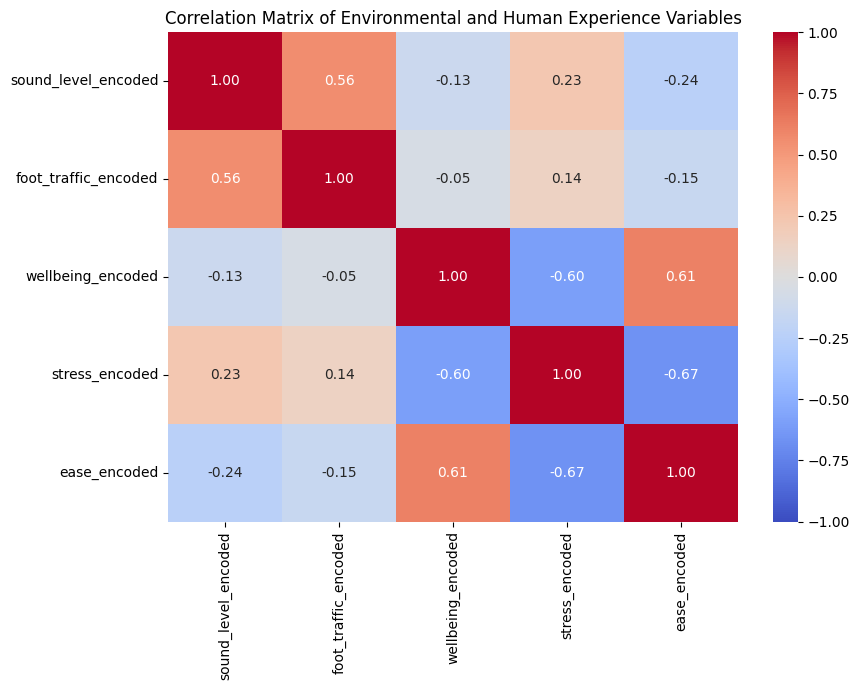

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Correct spelling mistakes in ease ratings
df_clean['ease_rating'] = df_clean['ease_rating'].replace({
    'Slighly uneasy': 'Slightly uneasy',
    'Vey easy': 'Very easy'
})

#Encode the corrected ease ratings
ease_mapping = {
    'Very uneasy': 0,
    'Slightly uneasy': 1,
    'Neutral': 2,
    'Easy': 3,
    'Very easy': 4
}

df_clean['ease_encoded'] = (
    df_clean['ease_rating'].map(ease_mapping)
)

print("Unmapped ease values:")
print(df_clean['ease_encoded'].isnull().sum())

correlation_columns = [
    'sound_level_encoded',
    'foot_traffic_encoded',
    'wellbeing_encoded',
    'stress_encoded',
    'ease_encoded'
]

correlation_data = df_clean[correlation_columns]

print("\nMissing values:")
print(correlation_data.isnull().sum())

correlation_matrix = correlation_data.corr(
    method='spearman'
)

# Display the correlation matrix
print("\nSpearman Correlation Matrix:")
display(correlation_matrix.round(2))

# Create the correlation heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f'
)

plt.title(
    'Correlation Matrix of Environmental and Human Experience Variables'
)

plt.tight_layout()
plt.show()

###Interpretation - Correlation Matrix Heatmap

I used Spearman correlation because the variables I encoded are ordinal categorical data. The heatmap helped me compare several variables at the same time using colours and numerical values.

Looking at the results, I noticed that sound levels and foot traffic had a moderate positive correlation of 0.56. This suggests that areas with more foot traffic also tend to have higher sound levels, which I found interesting.

I also noticed a moderate negative correlation between wellbeing and stress (-0.60). This suggests that observations with higher wellbeing ratings tend to have lower stress ratings.

Another interesting result was the positive correlation between wellbeing and ease (0.61), suggesting that people who felt more at ease also tended to report better wellbeing.

I also noticed a negative correlation between stress and ease (-0.67). This was one of the strongest relationships in my heatmap and suggests that people who felt more at ease tended to report lower stress levels.

The correlation between sound levels and stress was only 0.23, which indicates a weak positive relationship. I found this interesting because I initially expected sound levels to have a stronger relationship with stress.

I learned that correcting the spelling mistakes in the ease ratings made a difference to my correlation results. This helped me understand how important data cleaning is, even after starting the analysis.

Overall, the heatmap helped me investigate the relationships between environmental characteristics and human experience, which is the main research question of my project.

However, I understand that correlation does not prove causation and that other environmental factors could also influence the results.

#**Machine Learning Implementation**


##Introduction

After cleaning my dataset, creating graphs and completing the correlation analysis, I am now starting the machine-learning part of my project.

My lecturer showed us K-Means Clustering and Linear Regression during the lab, but I have never used K-Means Clustering before, so I want to understand how it works before trying it with my own dataset.

I want to investigate whether machine learning can help me find patterns in the campus observations, especially when looking at environmental factors such as sound levels and foot traffic.

I think this will be interesting because I have already explored some relationships using graphs and a correlation matrix, and now I want to see what else I can discover using machine learning.

I will start by understanding how K-Means Clustering works and then decide how to apply it to my dataset.


## K-Means Clustering


K-Means Clustering is an unsupervised machine-learning method that groups similar observations together.

From what I understand, the algorithm looks at the numerical values in the dataset and tries to organise observations into different groups, called clusters.

For my project, I want to investigate whether the campus observations can be grouped based on sound levels and foot traffic.

I have already encoded these variables, so I can now use their numerical values to explore how clustering works.

I also understand that I will need to choose the number of clusters and check whether the groups are meaningful.

In [ ]:
environmental_features = [
    'sound_level_encoded',
    'foot_traffic_encoded'
]

# Create a copy of selected features
X = df_clean[environmental_features].copy()

print("Selected Environmental Features:")
display(X.head())

# Check missing values
print("\nMissing Values:")
print(X.isnull().sum())

print("\nDataset Shape:")
print(X.shape)

print("\nSummary Statistics:")
display(X.describe())


Selected Environmental Features:


,sound_level_encoded,foot_traffic_encoded
0,0,0
1,1,0
2,0,0
3,1,0
4,1,0



Missing Values:
sound_level_encoded     0
foot_traffic_encoded    0
dtype: int64

Dataset Shape:
(135, 2)

Summary Statistics:


,sound_level_encoded,foot_traffic_encoded
count,135.000000,135.000000
mean,0.696296,0.385185
std,0.683211,0.657735
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,0.000000
75%,1.000000,1.000000
max,2.000000,2.000000


###Interpretation - Preparing Data for K-Means Clustering

I selected sound levels and foot traffic because I wanted to investigate whether campus observations could be grouped based on similar environmental characteristics.

After checking the data, I found that there were 135 observations and no missing values in either column.

Both variables had numerical values from 0 to 2 because I had already encoded them during the data preparation stage.

This means I can use all 135 observations for my initial clustering experiment without removing any additional rows.

I also understand that these numbers represent ordered categories rather than exact measurements, so I will need to be careful when interpreting the clusters.

### Choosing the Number of Clusters - Elbow Method

I have not used the Elbow Method before, so I want to understand how it can help me choose the number of clusters for K-Means.

The method compares different numbers of clusters and measures how closely the observations are grouped together.

I will create a graph to see whether there is a point where adding more clusters stops making a large improvement.

I think this will be useful because I want to make a decision based on the results rather than choosing the number of clusters without checking.

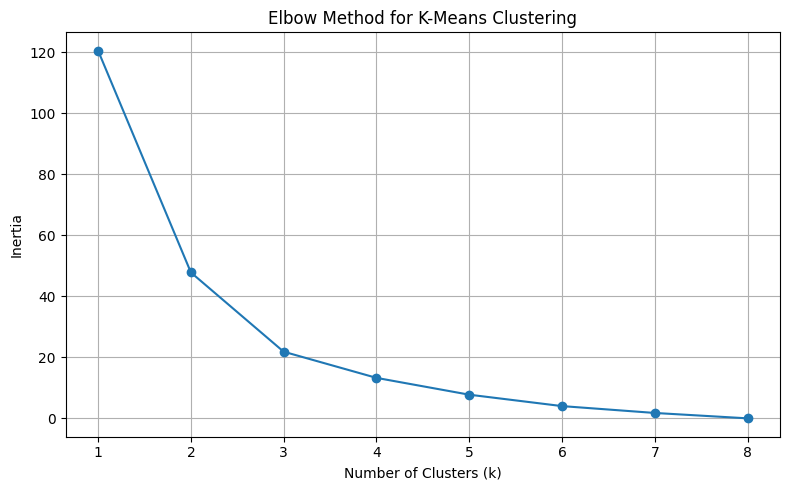

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test different numbers of clusters
k_values = range(1, 9)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

# Create the Elbow Method graph
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker='o')

plt.title('Elbow Method for K-Means Clustering')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()


###Interpretation - Elbow Method

I used the Elbow Method because I wanted to find a suitable number of clusters for K-Means instead of choosing a number randomly.

Looking at the graph, I noticed that inertia decreased a lot between 1 and 3 clusters. After 3 clusters, the line started to flatten, meaning that adding more clusters gave smaller improvements.

Based on this, I decided to start by testing 3 clusters.

I also noticed a warning when testing 9 clusters. I learned that my dataset only contains 8 different combinations of sound levels and foot traffic, so K-Means could not create 9 distinct clusters.

This helped me understand how the Elbow Method works and why checking the results is important before choosing the number of clusters.

### Applying K-Means Clustering

In [ ]:

import pandas as pd
from sklearn.cluster import KMeans

# Select environmental features
environmental_features = [
    'sound_level_encoded',
    'foot_traffic_encoded'
]

# Prepare the data
X = df_clean[environmental_features].copy()

# Create the K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Apply K-Means Clustering
cluster_labels = kmeans.fit_predict(X)

# Save the cluster labels
df_clean['cluster'] = cluster_labels

# Display the first five observations
print("First five observations:")
display(
    df_clean[
        environmental_features + ['cluster']
    ].head()
)

# Show observations in each cluster
print("\nObservations in each cluster:")
print(df_clean['cluster'].value_counts().sort_index())

# Display cluster centres
print("\nCluster centres:")
display(
    pd.DataFrame(
        kmeans.cluster_centers_,
        columns=environmental_features
    ).round(2)
)


First five observations:


,sound_level_encoded,foot_traffic_encoded,cluster
0,0,0,1
1,1,0,2
2,0,0,1
3,1,0,2
4,1,0,2



Observations in each cluster:
cluster
0    37
1    58
2    40
Name: count, dtype: int64

Cluster centres:


,sound_level_encoded,foot_traffic_encoded
0,1.38,1.35
1,0.00,0.03
2,1.08,0.00


###Interpretation - K-Means Clustering

I used K-Means Clustering with 3 clusters because the Elbow Method suggested that this could be a suitable number.

After running the code, I noticed that the 135 campus observations were divided into three groups.

Cluster 0 contained 37 observations and appeared to represent busier environments with higher sound levels and foot traffic.

Cluster 1 contained 58 observations and appeared to represent quieter environments with very low foot traffic.

Cluster 2 contained 40 observations and appeared to represent areas with moderate sound levels but low foot traffic.

I found this interesting because I could see that campus environments can have different characteristics, even when they have similar levels of foot traffic.

This helped me understand how K-Means can group observations based on similarities without using predefined labels.

I also understand that the results depend on the numerical values I assigned during encoding, so the clusters need to be interpreted carefully.

### Visualising K-Means Clusters

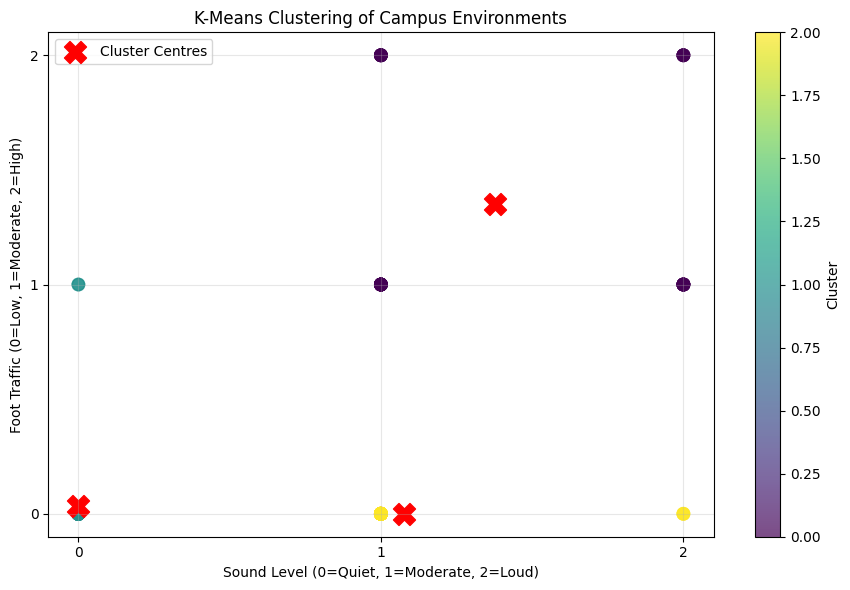

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X['sound_level_encoded'],
    X['foot_traffic_encoded'],
    c=df_clean['cluster'],
    cmap='viridis',
    s=80,
    alpha=0.7
)

# Show cluster centres
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=250,
    c='red',
    label='Cluster Centres'
)

plt.title('K-Means Clustering of Campus Environments')
plt.xlabel('Sound Level (0=Quiet, 1=Moderate, 2=Loud)')
plt.ylabel('Foot Traffic (0=Low, 1=Moderate, 2=High)')
plt.xticks([0, 1, 2])
plt.yticks([0, 1, 2])
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


###Interpretation - Visualising K-Means Clusters

I created a scatter plot because I wanted to see how K-Means divided the campus observations into different groups based on sound levels and foot traffic.

Looking at the graph, I noticed that the observations were divided into three clusters. Cluster 0 represented busier environments with higher sound levels and foot traffic, while Cluster 1 represented quieter areas with very low foot traffic. Cluster 2 represented areas with moderate or loud sound levels but low foot traffic.

I also noticed the red X symbols, which represent the centre of each cluster.

I found this interesting because some areas had higher sound levels even when foot traffic was low. This suggests that noise around campus may also come from other sources, such as traffic or construction.

I learned that K-Means can help identify patterns in a dataset without being told beforehand which group each observation belongs to.

However, I understand that some observations overlap on the graph because I used encoded categorical variables. I also know that the results depend on how these categories were converted into numbers.

### Comparing Clusters with Wellbeing and Stress

I want to investigate whether the three clusters identified by K-Means are associated with different wellbeing and stress ratings.

The clusters were created using sound levels and foot traffic, so wellbeing and stress were not used to decide which observations belonged to each group.

I will compare the percentages of wellbeing and stress responses within each cluster to see whether any interesting patterns appear.

This will help me connect the machine-learning results to the main research question of my project.

In [ ]:
import pandas as pd

# Wellbeing ratings by cluster
print("Wellbeing Ratings by Cluster (%):")

cluster_wellbeing = pd.crosstab(
    df_clean['cluster'],
    df_clean['wellbeing_rating'],
    normalize='index'
) * 100

display(cluster_wellbeing.round(1))

# Stress ratings by cluster
print("\nStress Ratings by Cluster (%):")

cluster_stress = pd.crosstab(
    df_clean['cluster'],
    df_clean['stress_rating'],
    normalize='index'
) * 100

display(cluster_stress.round(1))

print("\nNumber of Observations in Each Cluster:")
print(df_clean['cluster'].value_counts().sort_index())


Wellbeing Ratings by Cluster (%):


wellbeing_rating,Low wellbeing,Neutral,Positive wellbeing,Very low wellbeing,Very positive wellbeing
cluster,,,,,
0,5.4,32.4,56.8,0.0,5.4
1,6.9,24.1,48.3,1.7,19.0
2,5.0,30.0,50.0,2.5,12.5



Stress Ratings by Cluster (%):


stress_rating,Mostly calm,Neutral,Stressful,Very calm,Very stressful
cluster,,,,,
0,54.1,29.7,8.1,8.1,0.0
1,43.1,22.4,3.4,31.0,0.0
2,35.0,35.0,5.0,22.5,2.5



Number of Observations in Each Cluster:
cluster
0    37
1    58
2    40
Name: count, dtype: int64


###Interpretation – Comparing Clusters with Wellbeing and Stress

After applying K-Means Clustering, I wanted to see whether the three groups had different wellbeing and stress ratings.

Looking at the results, I noticed that Cluster 1, which represented quieter environments with very low foot traffic, had the highest percentage of very positive wellbeing ratings (19%).

Cluster 0, which represented busier environments, had the lowest percentage of very positive wellbeing ratings (5.4%).

I also noticed that Cluster 1 had the highest percentage of very calm responses (31%), compared with Cluster 0 (8.1%) and Cluster 2 (22.5%).

I found this interesting because it suggests that quieter environments might be associated with feeling calmer and having more positive wellbeing.

However, I also noticed that Cluster 0 had the highest percentage of ordinary positive wellbeing ratings (56.8%), so the results are not completely straightforward.

This helped me understand that machine learning can identify groups in the dataset, but I still need to analyse the results to understand what they mean.

I also understand that K-Means does not prove that environmental characteristics directly cause changes in wellbeing or stress.

###Evaluating K-Means Clustering

In [ ]:
from sklearn.metrics import silhouette_score

# Calculate the silhouette score
score = silhouette_score(X, df_clean['cluster'])

print("Silhouette Score:", round(score, 3))

print("K-Means Inertia:", round(kmeans.inertia_, 3))


Silhouette Score: 0.784
K-Means Inertia: 21.841


###Interpretation - Evaluating K-Means Clustering

After applying K-Means Clustering, I wanted to check how well the observations were grouped together.

I used the Silhouette Score to evaluate the clusters and obtained a result of 0.784. From what I understand, this is a relatively high score, suggesting that the three clusters are well separated.

I also checked the K-Means Inertia, which was 21.841. I learned that inertia measures how close the observations are to their cluster centres and can help compare different numbers of clusters.

I found these results interesting because I had never used K-Means before, and I was able to apply it to my own campus dataset.

However, I understand that I used encoded categorical data, so the results depend on how I assigned the numerical values. This means I need to be careful when interpreting how meaningful the clusters are.

Overall, this helped me understand how machine-learning results can be evaluated rather than just creating a model and assuming it works correctly.

##Linear Regression

After using K-Means Clustering, I now want to explore Linear Regression because it is another machine-learning method introduced by my lecturer.

From what I understand, Linear Regression is used to investigate relationships between numerical variables and make predictions.

For my project, I want to investigate whether environmental characteristics, such as sound levels and foot traffic, can help predict human experiences such as stress or wellbeing.

I have already encoded these variables into numerical values, but I understand that the original ratings are categories rather than exact measurements.

I want to investigate whether Linear Regression is suitable for my dataset and understand its limitations before applying it.

In [ ]:
import pandas as pd

# Select numerical columns
numerical_columns = df_clean.select_dtypes(
    include='number'
)

print("Numerical columns:")
print(numerical_columns.columns.tolist())

print("\nFirst five rows:")
display(numerical_columns.head())

print("\nMissing values:")
print(numerical_columns.isnull().sum())

print("\nSummary statistics:")
display(numerical_columns.describe())


Numerical columns:
['insects_count', 'birds_count', 'sound_level_encoded', 'foot_traffic_encoded', 'wellbeing_encoded', 'stress_encoded', 'ease_encoded', 'cluster']

First five rows:


,insects_count,birds_count,sound_level_encoded,foot_traffic_encoded,wellbeing_encoded,stress_encoded,ease_encoded,cluster
0,0.0,1.0,0,0,3,3,2,1
1,0.0,2.0,1,0,3,2,2,2
2,10.0,20.0,0,0,3,1,3,1
3,0.0,2.0,1,0,3,2,2,2
4,0.0,0.0,1,0,3,1,3,2



Missing values:
insects_count           0
birds_count             0
sound_level_encoded     0
foot_traffic_encoded    0
wellbeing_encoded       0
stress_encoded          0
ease_encoded            0
cluster                 0
dtype: int64

Summary statistics:


,insects_count,birds_count,sound_level_encoded,foot_traffic_encoded,wellbeing_encoded,stress_encoded,ease_encoded,cluster
count,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000
mean,2.733333,1.992593,0.696296,0.385185,2.688889,1.185185,2.644444,1.022222
std,5.106624,2.789897,0.683211,0.657735,0.832786,0.865467,0.918034,0.757713
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,2.000000,0.000000
50%,1.000000,1.000000,1.000000,0.000000,3.000000,1.000000,3.000000,1.000000
75%,3.000000,3.000000,1.000000,1.000000,3.000000,2.000000,3.000000,2.000000
max,31.000000,20.000000,2.000000,2.000000,4.000000,4.000000,4.000000,2.000000


###Checking Missing Values in Ease Rating Encoding

In [ ]:
print("Original Ease Rating Categories:")
print(df_clean['ease_rating'].value_counts(dropna=False))

print("\nEase Rating Encoding Comparison:")
display(
    df_clean[['ease_rating', 'ease_encoded']]
    .drop_duplicates()
)

# Identify values that were not encoded
print("\nUnmapped Ease Ratings:")
print(
    df_clean.loc[
        df_clean['ease_encoded'].isna(),
        'ease_rating'
    ].value_counts(dropna=False)
)


Original Ease Rating Categories:
ease_rating
Easy               58
Neutral            38
Very easy          23
Slightly uneasy    15
Very uneasy         1
Name: count, dtype: int64

Ease Rating Encoding Comparison:


,ease_rating,ease_encoded
0,Neutral,2
2,Easy,3
7,Very easy,4
22,Very uneasy,0
24,Slightly uneasy,1



Unmapped Ease Ratings:
Series([], Name: count, dtype: int64)


###Correcting Ease Rating Categories

In [ ]:
df_clean['ease_rating'] = df_clean['ease_rating'].replace({
    'Slighly uneasy': 'Slightly uneasy',
    'Vey easy': 'Very easy'
})

# Create the correct ordinal mapping
ease_mapping = {
    'Very uneasy': 0,
    'Slightly uneasy': 1,
    'Neutral': 2,
    'Easy': 3,
    'Very easy': 4
}

df_clean['ease_encoded'] = (
    df_clean['ease_rating'].map(ease_mapping)
)

print("Corrected Ease Rating Encoding:")

display(
    df_clean[['ease_rating', 'ease_encoded']]
    .drop_duplicates()
    .sort_values(by='ease_encoded')
)

print("\nUnmapped values:")
print(df_clean['ease_encoded'].isnull().sum())


Corrected Ease Rating Encoding:


,ease_rating,ease_encoded
22,Very uneasy,0
24,Slightly uneasy,1
0,Neutral,2
2,Easy,3
7,Very easy,4



Unmapped values:
0


###Interprentation - Missing Values in Ease Rating Encoding



While preparing my data for Linear Regression, I discovered that 38 ease ratings had not been encoded correctly because of two spelling mistakes. After correcting them, I updated my correlation matrix and noticed that some of the relationships had changed. This helped me understand how important it is to check the data carefully because even small mistakes can affect the results.

### Preparing Data for Linear Regression

After correcting the missing encoded values, I wanted to prepare my data for Linear Regression.

I decided to investigate whether sound levels and foot traffic could help predict wellbeing ratings.

I chose these variables because I had already used them during my K-Means Clustering analysis, and I wanted to explore their relationship with wellbeing using a different machine-learning method.

I understand that wellbeing ratings are ordered categories rather than exact numerical measurements, so Linear Regression will only give me an approximate prediction.

I will first separate the input variables from the wellbeing ratings and then divide the data into training and testing sets.

In [ ]:

from sklearn.model_selection import train_test_split

# Select input variables
X_reg = df_clean[
    ['sound_level_encoded', 'foot_traffic_encoded']
]

# Select target variable
y_reg = df_clean['wellbeing_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nMissing input values:")
print(X_reg.isnull().sum())

print("\nMissing target values:")
print(y_reg.isnull().sum())


Training observations: 108
Testing observations: 27

Missing input values:
sound_level_encoded     0
foot_traffic_encoded    0
dtype: int64

Missing target values:
0


###Interpretation - Preparing Data for Linear Regression

I divided my dataset into training and testing sets because I wanted to evaluate how well Linear Regression could make predictions using data it had not seen before.

I used 80% of the observations for training and 20% for testing, which gave me 108 training observations and 27 testing observations.

I also checked for missing values and found that both my input variables and the wellbeing ratings had no missing values.

This helped me understand why separating the data is important before training a machine-learning model.

###Training the Linear Regression Model

In this section, I want to train a Linear Regression model to investigate whether sound levels and foot traffic can help predict wellbeing ratings.

I will use the training data to teach the model how the input variables relate to wellbeing.

After training, I will use the testing data to make predictions and compare them with the actual wellbeing ratings.

I understand that wellbeing ratings are ordinal categories, so the predictions will be approximate numerical scores rather than exact categories.

In [ ]:
from sklearn.linear_model import LinearRegression
import pandas as pd

# Create the model
reg_model = LinearRegression()

# Train the model
reg_model.fit(X_train, y_train)

y_pred = reg_model.predict(X_test)

print("Model intercept:", round(reg_model.intercept_, 3))

print("\nModel coefficients:")
display(
    pd.DataFrame({
        'Feature': X_train.columns,
        'Coefficient': reg_model.coef_
    }).round(3)
)

# Compare actual and predicted wellbeing scores
print("\nActual vs Predicted Wellbeing:")
display(
    pd.DataFrame({
        'Actual Wellbeing': y_test.values,
        'Predicted Wellbeing': y_pred
    }).head(10).round(2)
)


Model intercept: 2.735

Model coefficients:


,Feature,Coefficient
0,sound_level_encoded,-0.163
1,foot_traffic_encoded,0.085



Actual vs Predicted Wellbeing:


,Actual Wellbeing,Predicted Wellbeing
0,4,2.73
1,3,2.58
2,3,2.82
3,4,2.73
4,2,2.41
5,3,2.73
6,3,2.66
7,3,2.73
8,3,2.57
9,3,2.66


###Interpretation - Training Linear Regression

After training my Linear Regression model, I compared the predicted wellbeing scores with the actual ratings.

I noticed that the coefficient for sound level was -0.163, while the coefficient for foot traffic was 0.085. This suggests that higher sound levels may be associated with slightly lower predicted wellbeing scores, while foot traffic showed a small positive relationship.

Looking at the first ten predictions, I noticed that most predicted values were between 2 and 3, even when some actual wellbeing ratings were 4.

I found this interesting because I expected the predictions to be closer to the actual ratings.

I understand that wellbeing ratings are categories rather than exact numerical measurements, so Linear Regression has limitations when applied to this type of data.

I will now evaluate the model to understand how accurate its predictions are.

###Evaluating Linear Regression

After training my Linear Regression model, I want to check how well it predicts wellbeing ratings.

I will use Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R² to evaluate the predictions.

From what I understand, MAE and RMSE measure the differences between the predicted and actual values, while R² helps explain how much variation in the wellbeing scores the model accounts for.

I want to use these results to understand whether sound levels and foot traffic are useful for predicting wellbeing in my dataset.

In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Linear Regression Evaluation:")
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R-squared (R²):", round(r2, 3))

# Compare against a simple baseline prediction
baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)

print("\nBaseline Mean Absolute Error:",
      round(mean_absolute_error(y_test, baseline_pred), 3))


Linear Regression Evaluation:
Mean Absolute Error (MAE): 0.619
Root Mean Squared Error (RMSE): 0.728
R-squared (R²): -0.018

Baseline Mean Absolute Error: 0.621


###Interpretation - Evaluating Linear Regression

After training my Linear Regression model, I wanted to check how accurate its predictions were.

I used MAE, RMSE and R² to evaluate the model. The MAE was 0.619 and the RMSE was 0.728, showing that there were differences between the predicted and actual wellbeing scores.

I also noticed that the R² value was -0.018, which means the model did not explain the differences in wellbeing ratings very well.

When I compared the model with a simple baseline, I found that the MAE was only slightly better (0.619 compared with 0.621).

I found this interesting because I initially expected the model to make more accurate predictions using sound levels and foot traffic.

This helped me understand that machine learning does not always produce strong predictions and that evaluating the results is important.

I also understand that wellbeing ratings are categorical rather than exact numerical measurements, so Linear Regression has limitations when used with this type of data.

#**Conclusion and reflections**

In this project, I explored how environmental characteristics around the ATU Galway campus might be related to people's wellbeing and experiences.

I started by cleaning and exploring my dataset using Python. I then created different graphs to investigate sound levels, foot traffic, trees, stress and wellbeing. I found it interesting that quieter environments were associated with calmer responses, but I also noticed that the relationship between nature and wellbeing was not always as straightforward as I expected.

One of the most important things I learned was how small mistakes in the data can affect the results. For example, while preparing my data for Linear Regression, I discovered that some ease ratings had not been encoded correctly because of spelling mistakes. I corrected them and updated my correlation matrix. This helped me understand why checking the data carefully is so important.

I also used K-Means Clustering for the first time. At the beginning, I did not really understand how it worked, but after applying the Elbow Method and evaluating the clusters, I started to understand how machine learning can identify patterns in data.

When I tried Linear Regression, I expected better predictions, but the results were not very strong (R² = -0.018). I found this useful because I learned that a machine-learning model does not always give accurate results and that understanding why is part of the analysis.

Overall, this project helped me become more confident using Python, Pandas and machine-learning techniques. I learned that working with data is not just about writing code but also about making decisions, identifying mistakes and interpreting results carefully.

I also understood that finding a relationship between variables does not mean that one directly causes the other. If I continued this project, I would like to investigate more environmental factors and explore other machine-learning methods to see whether they could give more useful results.